# Credit Card Fraud Detection - Classification

# Algorithms: Logistic Regression, Random Forest, XGBoost

# Metrics: AUPRC (primary), F1-score, Precision, Recall (accuracy is not meaningful here)

# 1. Imports

In [2]:
import glob
import warnings
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from xgboost import XGBClassifier
 
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

# 2. Load data (works on Kaggle and locally)

In [3]:
paths = glob.glob("/kaggle/input/**/creditcard.csv", recursive=True) + \
        glob.glob("creditcard.csv") + glob.glob("data/creditcard.csv")
if not paths:
    raise FileNotFoundError("creditcard.csv not found. On Kaggle use 'Add Input' -> "
                            "'Credit Card Fraud Detection' (mlg-ulb). Locally, put it in ./data/")
df = pd.read_csv(paths[0])
print(f"Loaded {paths[0]}: {df.shape}")
df.head()

Loaded /kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# 3. Basic info

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
counts = df["Class"].value_counts()
print(f"\nLegit: {counts[0]:,}  Fraud: {counts[1]:,}  ({counts[1] / len(df) * 100:.3f}% fraud)")
df = df.drop_duplicates().reset_index(drop=True)

Missing values: 0
Duplicate rows: 1081

Legit: 284,315  Fraud: 492  (0.173% fraud)


# 4. EDA

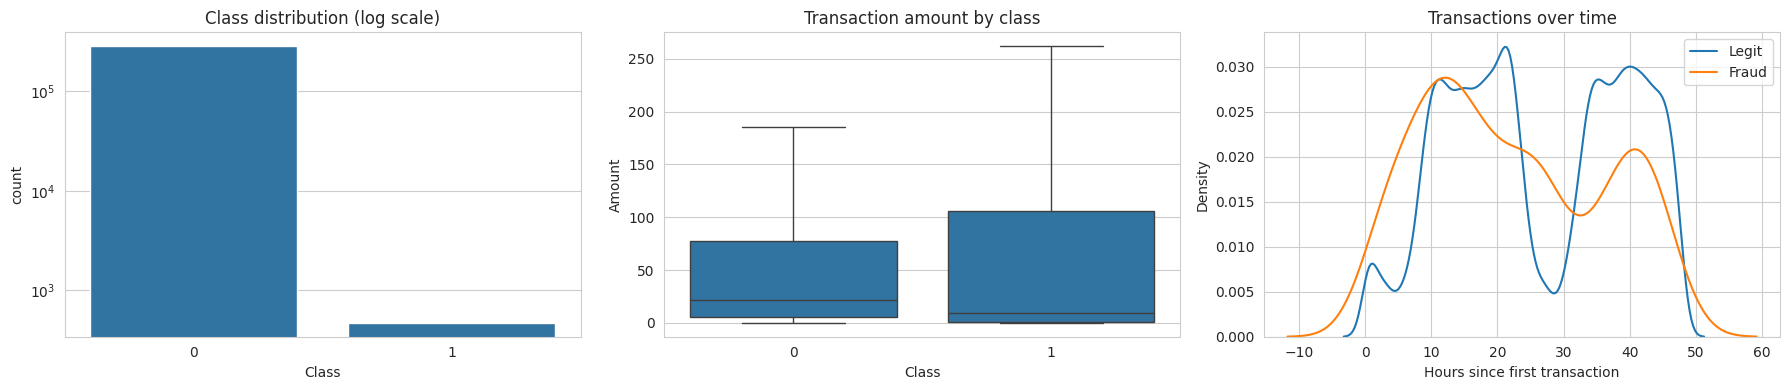

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(x="Class", data=df, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Class distribution (log scale)")
 
sns.boxplot(x="Class", y="Amount", data=df, ax=axes[1], showfliers=False)
axes[1].set_title("Transaction amount by class")
 
sns.kdeplot(df.loc[df.Class == 0, "Time"] / 3600, label="Legit", ax=axes[2])
sns.kdeplot(df.loc[df.Class == 1, "Time"] / 3600, label="Fraud", ax=axes[2])
axes[2].set_xlabel("Hours since first transaction")
axes[2].set_title("Transactions over time")
axes[2].legend()
plt.tight_layout()
plt.show()

# Which PCA components correlate most with fraud?

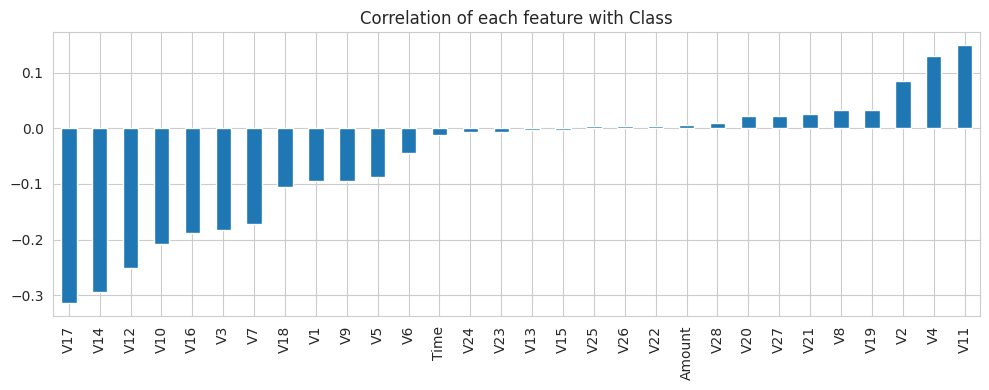

In [6]:
corr = df.corr()["Class"].drop("Class").sort_values()
plt.figure(figsize=(10, 4))
corr.plot(kind="bar")
plt.title("Correlation of each feature with Class")
plt.tight_layout()
plt.show()

# 5. Split (stratified: train / validation / test) and scale Time & Amount

In [7]:
X = df.drop(columns="Class")
y = df["Class"]
 
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE)
 
scaler = StandardScaler().fit(X_train[["Time", "Amount"]])       # fit on train only
for part in (X_train, X_val, X_test):
    part[["Time", "Amount"]] = scaler.transform(part[["Time", "Amount"]])
 
print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")
print(f"Frauds -> train: {y_train.sum()}  val: {y_val.sum()}  test: {y_test.sum()}")

Train: (181584, 30)  Val: (45396, 30)  Test: (56746, 30)
Frauds -> train: 302  val: 76  test: 95


# 6. Models (imbalance handled with class weights, no resampling needed)

In [9]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
 
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", C=0.1, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=14, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=neg / pos, eval_metric="aucpr",
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
}

# 7. Train, pick the best threshold on VALIDATION data, evaluate on TEST data

In [10]:
def best_threshold(y_true, scores):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return t[np.argmax(f1)]
 
results, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    thr = best_threshold(y_val, model.predict_proba(X_val)[:, 1])
    test_scores = model.predict_proba(X_test)[:, 1]
    test_pred = (test_scores >= thr).astype(int)
 
    fitted[name] = (model, thr, test_scores, test_pred)
    results.append({
        "Model": name,
        "AUPRC": average_precision_score(y_test, test_scores),
        "F1": f1_score(y_test, test_pred) * 100,
        "Precision": precision_score(y_test, test_pred) * 100,
        "Recall": recall_score(y_test, test_pred) * 100,
        "Threshold": thr,
    })
    print(f"{name:20s} AUPRC={results[-1]['AUPRC']:.3f}  F1={results[-1]['F1']:.2f}")
 
res_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
print("\n=== Model comparison (test set) ===")
print(res_df.round(3).to_string(index=False))
 

Logistic Regression  AUPRC=0.674  F1=80.22
Random Forest        AUPRC=0.811  F1=81.21
XGBoost              AUPRC=0.821  F1=85.55

=== Model comparison (test set) ===
              Model  AUPRC     F1  Precision  Recall  Threshold
            XGBoost  0.821 85.549     94.872  77.895      0.670
      Random Forest  0.811 81.212     95.714  70.526      0.613
Logistic Regression  0.674 80.220     83.908  76.842      1.000


#  8. Precision-Recall curves

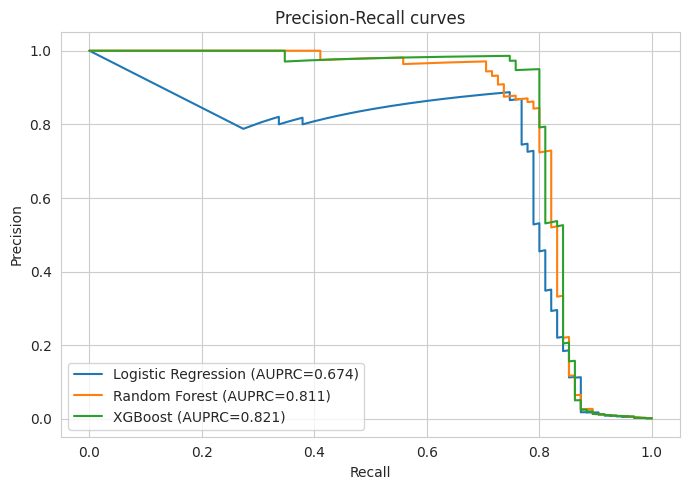

In [13]:
plt.figure(figsize=(7, 5))
for name, (_, _, scores, _) in fitted.items():
    p, r, _ = precision_recall_curve(y_test, scores)
    plt.plot(r, p, label=f"{name} (AUPRC={average_precision_score(y_test, scores):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Best model - report and confusion matrix

Best model: XGBoost | F1 = 85.55 | threshold = 0.670

              precision    recall  f1-score   support

       Legit      1.000     1.000     1.000     56651
       Fraud      0.949     0.779     0.855        95

    accuracy                          1.000     56746
   macro avg      0.974     0.889     0.928     56746
weighted avg      1.000     1.000     1.000     56746



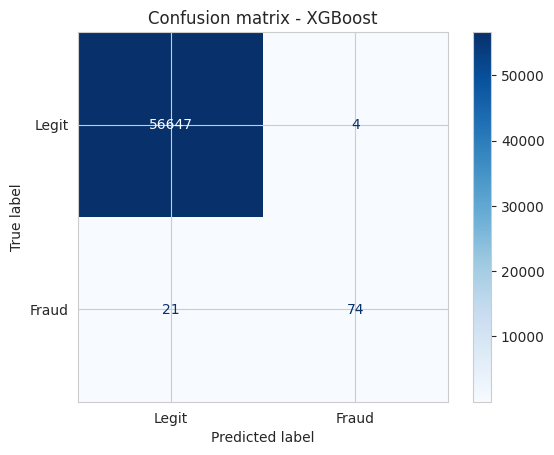

In [14]:
best_name = res_df.loc[0, "Model"]
best_model, best_thr, _, best_pred = fitted[best_name]
print(f"Best model: {best_name} | F1 = {res_df.loc[0, 'F1']:.2f} | threshold = {best_thr:.3f}\n")
print(classification_report(y_test, best_pred, target_names=["Legit", "Fraud"], digits=3))
 
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred),
                       display_labels=["Legit", "Fraud"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix - {best_name}")
plt.show()

# 10. Feature importance

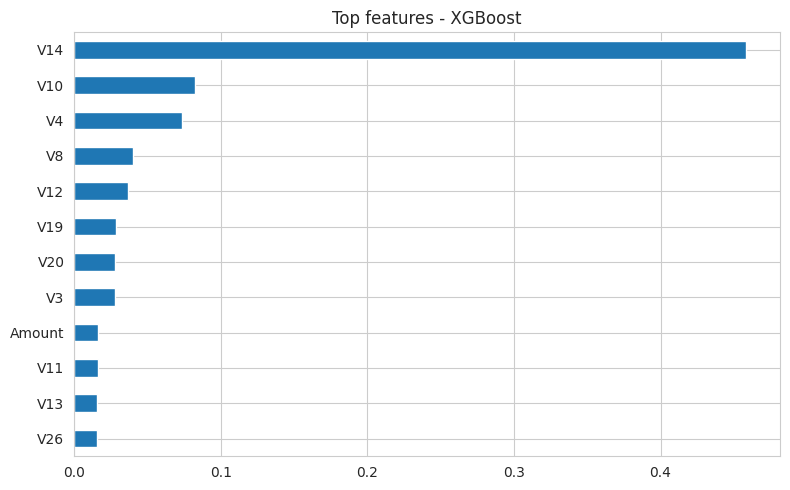

In [15]:
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=X.columns)
else:
    imp = pd.Series(np.abs(best_model.coef_[0]), index=X.columns)
plt.figure(figsize=(8, 5))
imp.sort_values().tail(12).plot(kind="barh")
plt.title(f"Top features - {best_name}")
plt.tight_layout()
plt.show()